Let's dive into the fascinating world of Support Vector Machines (SVMs)! This powerful supervised learning algorithm is used for both classification and regression tasks, but it's particularly well-known for its effectiveness in classification.

At its core, SVM aims to find an optimal hyperplane that separates data points into different classes. The "optimal" part refers to the hyperplane that has the largest margin between the closest data points of different classes.

Here's a detailed breakdown of SVM, including hard margin, soft margin, and kernel tricks:

---

### **1. The Goal of SVM: Optimal Hyperplane**

Imagine you have data points belonging to two classes. An SVM tries to draw a line (in 2D), a plane (in 3D), or a hyperplane (in higher dimensions) that best separates these classes.

The best separating line/plane/hyperplane is one that maximizes the **margin**. The margin is the distance between the hyperplane and the closest data points from each class. These closest data points are called **support vectors**.

**Visualizing the Margin:**

Let's start with a simple 2D example.

In this image:
* The solid line is the **optimal hyperplane**.
* The dashed lines are the **margin boundaries**.
* The data points circled are the **support vectors**.

---

### **2. Mathematical Formulation**

Let's denote our data points as $x_i \in \mathbb{R}^n$ and their corresponding class labels as $y_i \in \{-1, 1\}$. We are looking for a hyperplane defined by the equation:

$w \cdot x + b = 0$

Where:
* $w$ is the normal vector to the hyperplane (a vector perpendicular to the hyperplane).
* $b$ is the bias or intercept term.
* $x$ is a point on the hyperplane.

For any data point $x_i$, its distance from the hyperplane and its classification are determined by the sign of $w \cdot x_i + b$.

We want to ensure that for all data points:
* If $y_i = 1$, then $w \cdot x_i + b \ge 1$
* If $y_i = -1$, then $w \cdot x_i + b \le -1$

These two conditions can be combined into a single inequality:

$y_i (w \cdot x_i + b) \ge 1 \quad \forall i$

**Distance from a Point to a Hyperplane:**

The distance from a point $x_0$ to the hyperplane $w \cdot x + b = 0$ is given by:

$distance = \frac{|w \cdot x_0 + b|}{||w||}$

The margin is the distance between the two margin boundary hyperplanes. The points on these boundary hyperplanes (the support vectors) satisfy $w \cdot x_i + b = 1$ and $w \cdot x_i + b = -1$.

The distance between the hyperplane $w \cdot x + b = 1$ and the optimal hyperplane $w \cdot x + b = 0$ is $\frac{1}{||w||}$.
Similarly, the distance between $w \cdot x + b = -1$ and $w \cdot x + b = 0$ is also $\frac{1}{||w||}$.

Therefore, the total margin width is $\frac{2}{||w||}$.

Our goal is to **maximize this margin**, which is equivalent to **minimizing $||w||$**. For computational convenience, we often minimize $\frac{1}{2}||w||^2$.

---

### **3. Hard Margin SVM (Linear SVM for Linearly Separable Data)**

This is the simplest form of SVM, applicable when the data is **perfectly linearly separable** (i.e., you can draw a straight line/plane that separates the classes without any misclassifications).

**Optimization Problem:**

Minimize $\frac{1}{2} ||w||^2$
Subject to $y_i (w \cdot x_i + b) \ge 1 \quad \forall i$

This is a **convex optimization problem**, specifically a quadratic programming problem. It has a unique global minimum.

**Lagrangian Formulation:**

To solve this constrained optimization problem, we typically use the **Lagrangian multipliers**. We introduce a set of Lagrange multipliers $\alpha_i \ge 0$, one for each constraint.

The Lagrangian function $L(w, b, \alpha)$ is:

$L(w, b, \alpha) = \frac{1}{2} ||w||^2 - \sum_{i=1}^{N} \alpha_i [y_i (w \cdot x_i + b) - 1]$

To find the minimum, we take partial derivatives with respect to $w$ and $b$ and set them to zero:

$\frac{\partial L}{\partial w} = w - \sum_{i=1}^{N} \alpha_i y_i x_i = 0 \quad \Rightarrow \quad w = \sum_{i=1}^{N} \alpha_i y_i x_i$

$\frac{\partial L}{\partial b} = - \sum_{i=1}^{N} \alpha_i y_i = 0 \quad \Rightarrow \quad \sum_{i=1}^{N} \alpha_i y_i = 0$

Substitute the expression for $w$ back into the Lagrangian function, and apply the condition for $b$. After some algebraic manipulation, we arrive at the **dual optimization problem**:

Maximize $L_D(\alpha) = \sum_{i=1}^{N} \alpha_i - \frac{1}{2} \sum_{i=1}^{N} \sum_{j=1}^{N} \alpha_i \alpha_j y_i y_j (x_i \cdot x_j)$
Subject to $\alpha_i \ge 0 \quad \forall i$
And $\sum_{i=1}^{N} \alpha_i y_i = 0$

**Karush-Kuhn-Tucker (KKT) Conditions:**

The KKT conditions are crucial for understanding the solution:
$\alpha_i \ge 0$
$y_i (w \cdot x_i + b) - 1 \ge 0$
$\alpha_i [y_i (w \cdot x_i + b) - 1] = 0$

The last condition is particularly important:
* If $\alpha_i > 0$, then $y_i (w \cdot x_i + b) - 1 = 0$, which means $y_i (w \cdot x_i + b) = 1$. These are the **support vectors** – the data points that lie exactly on the margin boundaries.
* If $\alpha_i = 0$, then $y_i (w \cdot x_i + b) - 1 > 0$, meaning the point is correctly classified and lies outside the margin. These points do not influence the hyperplane.

**Steps for Hard Margin SVM:**

1.  **Formulate the Dual Problem:** Set up the quadratic programming problem as described above.
2.  **Solve for $\alpha_i$:** Use a quadratic programming solver to find the optimal $\alpha_i$ values.
3.  **Calculate $w$:** Use the equation $w = \sum_{i=1}^{N} \alpha_i y_i x_i$. Only the support vectors (where $\alpha_i > 0$) contribute to $w$.
4.  **Calculate $b$:** Choose any support vector $x_k$ (where $\alpha_k > 0$) and use the condition $y_k (w \cdot x_k + b) = 1$ to solve for $b$:
    
    $b = y_k - w \cdot x_k$ (or more robustly, average $b$ over all support vectors).
5.  **Classification:** For a new data point $x_{new}$, predict its class using the sign of the decision function:

    $f(x_{new}) = sign(w \cdot x_{new} + b)$

---

### **4. Soft Margin SVM (Linear SVM for Non-Linearly Separable Data)**

What if the data is not perfectly linearly separable, or if there are outliers that make the hard margin approach too sensitive? This is where **Soft Margin SVM** comes in.

Soft margin SVM allows for some misclassifications or violations of the margin, but it penalizes them. This is achieved by introducing **slack variables** $\xi_i$ (xi).

**Introducing Slack Variables:**

For each data point $x_i$, we introduce a slack variable $\xi_i \ge 0$:
* If $0 \le \xi_i < 1$: The data point is correctly classified but falls within the margin.
* If $\xi_i \ge 1$: The data point is misclassified.

The new constraints become:
$y_i (w \cdot x_i + b) \ge 1 - \xi_i \quad \forall i$
$\xi_i \ge 0$

**Optimization Problem:**

We now want to minimize not only $||w||^2$ but also a penalty for the slack variables. We introduce a regularization parameter $C > 0$.

Minimize $\frac{1}{2} ||w||^2 + C \sum_{i=1}^{N} \xi_i$
Subject to $y_i (w \cdot x_i + b) \ge 1 - \xi_i \quad \forall i$
And $\xi_i \ge 0 \quad \forall i$

**Parameter C:**
* **Small C:** Allows more misclassifications and a wider margin (more regularization).
* **Large C:** Penalizes misclassifications heavily, leading to a narrower margin and potentially overfitting.

**Dual Optimization Problem for Soft Margin SVM:**

Following a similar Lagrangian approach, the dual problem for soft margin SVM is:

Maximize $L_D(\alpha) = \sum_{i=1}^{N} \alpha_i - \frac{1}{2} \sum_{i=1}^{N} \sum_{j=1}^{N} \alpha_i \alpha_j y_i y_j (x_i \cdot x_j)$
Subject to $0 \le \alpha_i \le C \quad \forall i$
And $\sum_{i=1}^{N} \alpha_i y_i = 0$

Notice the only change from the hard margin dual problem is the upper bound on $\alpha_i$ (i.e., $\alpha_i \le C$).

**KKT Conditions for Soft Margin SVM:**
* $\alpha_i \ge 0$
* $y_i (w \cdot x_i + b) - 1 + \xi_i = 0$
* $\xi_i \ge 0$
* $\alpha_i [y_i (w \cdot x_i + b) - 1 + \xi_i] = 0$
* $(C - \alpha_i) \xi_i = 0$

From these conditions, we can deduce:
* If $\alpha_i = 0$: The point is correctly classified and outside the margin. $\xi_i = 0$.
* If $0 < \alpha_i < C$: The point is a support vector and lies on the margin boundary ($y_i (w \cdot x_i + b) = 1$). $\xi_i = 0$.
* If $\alpha_i = C$: The point is either within the margin ($0 < \xi_i < 1$) or misclassified ($\xi_i \ge 1$). These are "margin error" or "misclassified" support vectors.

The steps for solving soft margin SVM are identical to hard margin, but with the modified bounds for $\alpha_i$.

---

### **5. Kernel Trick (Non-Linear SVM)**

The linear SVM (both hard and soft margin) works well when data is linearly separable. But what if the data is inherently non-linear?

**The Challenge of Non-Linearity:**

Consider the XOR problem, where a straight line cannot separate the classes.

This data is clearly not linearly separable in its original 2D space.

**The Idea: Mapping to a Higher-Dimensional Space:**

The core idea of the kernel trick is to implicitly map the input features into a much higher-dimensional feature space where the data *might* become linearly separable.

Let $\phi(x)$ be a transformation function that maps the original data $x$ into a higher-dimensional space:

$\phi: \mathbb{R}^n \rightarrow \mathbb{R}^m \quad \text{where } m \gg n$

In this new space, we can then apply a linear SVM. The hyperplane in the higher-dimensional space will correspond to a non-linear decision boundary in the original input space.

**The "Trick": Avoid Explicit Mapping:**

If $m$ is very large (potentially infinite), explicitly calculating $\phi(x)$ and then computing the dot product $\phi(x_i) \cdot \phi(x_j)$ can be computationally expensive or even impossible.

The "trick" is that the SVM dual problem only requires the **dot product** of data points: $(x_i \cdot x_j)$. If we map to a higher dimension, we need $\phi(x_i) \cdot \phi(x_j)$.

A **kernel function**, denoted by $K(x_i, x_j)$, is a function that directly computes this dot product in the higher-dimensional space **without explicitly performing the mapping $\phi(x)$**:

$K(x_i, x_j) = \phi(x_i) \cdot \phi(x_j)$

By replacing every occurrence of $x_i \cdot x_j$ in the dual problem with $K(x_i, x_j)$, we can find a non-linear decision boundary.

**Dual Optimization Problem with Kernel:**

Maximize $L_D(\alpha) = \sum_{i=1}^{N} \alpha_i - \frac{1}{2} \sum_{i=1}^{N} \sum_{j=1}^{N} \alpha_i \alpha_j y_i y_j K(x_i, x_j)$
Subject to $0 \le \alpha_i \le C \quad \forall i$
And $\sum_{i=1}^{N} \alpha_i y_i = 0$

**Decision Function with Kernel:**

The weight vector $w$ cannot be explicitly computed in the original space. However, the decision function for a new point $x_{new}$ can still be calculated:

$w \cdot \phi(x_{new}) + b = \left( \sum_{i=1}^{N} \alpha_i y_i \phi(x_i) \right) \cdot \phi(x_{new}) + b$
$= \sum_{i=1}^{N} \alpha_i y_i (\phi(x_i) \cdot \phi(x_{new})) + b$$ = \sum_{i=1}^{N} \alpha_i y_i K(x_i, x_{new}) + b$

So, the classification for a new point $x_{new}$ is:
$f(x_{new}) = sign \left( \sum_{i=1}^{N} \alpha_i y_i K(x_i, x_{new}) + b \right)$

Only support vectors (where $\alpha_i > 0$) contribute to this sum.

**Popular Kernel Functions:**

1.  **Linear Kernel:**
    $K(x_i, x_j) = x_i \cdot x_j$
    (This is equivalent to the linear SVM without a kernel trick)

2.  **Polynomial Kernel:**
    $K(x_i, x_j) = (x_i \cdot x_j + r)^d$
    Where $d$ is the degree of the polynomial, and $r$ is a constant. This maps data into a polynomial feature space.

3.  **Radial Basis Function (RBF) Kernel / Gaussian Kernel:**
    $K(x_i, x_j) = \exp \left( - \gamma ||x_i - x_j||^2 \right)$
    Where $\gamma > 0$ is a free parameter. This is one of the most popular and powerful kernels. It maps data into an infinite-dimensional space.
    * Small $\gamma$: broader influence of individual support vectors, smoother decision boundary.
    * Large $\gamma$: closer influence, potentially more complex and wiggly decision boundary, risk of overfitting.

4.  **Sigmoid Kernel:**
    $K(x_i, x_j) = \tanh(\kappa x_i \cdot x_j + \theta)$
    Where $\kappa$ and $\theta$ are parameters.

**Choosing a Kernel:**

The choice of kernel function is often problem-dependent and can significantly impact the performance of the SVM. RBF is a good general-purpose choice. For high-dimensional sparse data (like text), linear kernels often work surprisingly well.

---

### **6. Steps for Non-Linear SVM with Kernel Trick**

1.  **Select a Kernel Function:** Choose an appropriate kernel (e.g., RBF, polynomial).
2.  **Formulate the Dual Problem with Kernel:** Replace dot products $x_i \cdot x_j$ with $K(x_i, x_j)$ in the soft margin dual problem.
3.  **Solve for $\alpha_i$:** Use a quadratic programming solver to find the optimal $\alpha_i$ values, respecting $0 \le \alpha_i \le C$.
4.  **Calculate $b$:**
For any support vector $x_k$ (where $0 < \alpha_k < C$), use the KKT condition $y_k (w \cdot \phi(x_k) + b) = 1$:
$b = y_k - \sum_{j=1}^{N} \alpha_j y_j K(x_j, x_k)$
(It's more numerically stable to average $b$ over all such support vectors).
5.  **Classification:**
For a new data point $x_{new}$, predict its class using the sign of the decision function:
$f(x_{new}) = sign( \sum_{i=1}^{N} \alpha_i y_i K(x_i, x_{new}) + b )$
---

### **Summary of Key Concepts**

* **Hyperplane:** The decision boundary that separates classes.
* **Margin:** The distance between the hyperplane and the closest training data points (support vectors). SVM seeks to maximize this.
* **Support Vectors:** The data points that lie on or within the margin boundaries and directly influence the position of the hyperplane.
* **Hard Margin SVM:** For perfectly linearly separable data; no misclassifications allowed.
* **Soft Margin SVM:** For non-linearly separable data or when tolerating some misclassifications/margin violations; uses slack variables ($\xi_i$) and a regularization parameter ($C$).
* **Kernel Trick:** Allows SVM to learn non-linear decision boundaries by implicitly mapping data to a higher-dimensional space where it might be linearly separable, without explicitly computing the high-dimensional coordinates. It does this by using kernel functions $K(x_i, x_j) = \phi(x_i) \cdot \phi(x_j)$.
* **Dual Problem:** The optimization formulation that is typically solved, leading to the use of kernel functions.
* **KKT Conditions:** Explain the relationship between the Lagrange multipliers ($\alpha_i$) and the data points (support vectors vs. non-support vectors).

SVMs are powerful and versatile algorithms due to their strong theoretical foundation and the flexibility offered by the kernel trick. They are particularly effective in high-dimensional spaces and cases with a clear margin of separation.

# 🧮 Full Step-by-Step SVM Example (Linear Kernel)

### Problem Setup

We have 3 training samples:

| i | xᵢ (features) | yᵢ (label) |
| - | ------------- | ---------- |
| 1 | (2, 3)        | +1 (cat)   |
| 2 | (3, 5)        | +1 (cat)   |
| 3 | (7, 8)        | −1 (dog)   |

Test point:  
$$
x_{\text{test}} = (3,4)
$$

Goal: predict whether it’s a cat (+1) or dog (−1).

We’ll use a **linear kernel**  
$$
K(x_i, x_j) = x_i \cdot x_j
$$

and assume a large penalty parameter \( C \) (so upper bounds on α don’t bind).

---

## Step 1 — Compute the Kernel Matrix \(K\)

Formula:
$$
K_{ij} = x_i \cdot x_j
$$

Compute each entry:
$$
\begin{aligned}
K_{11} &= 2\cdot2 + 3\cdot3 = 13 \\
K_{12} &= 2\cdot3 + 3\cdot5 = 21 \\
K_{13} &= 2\cdot7 + 3\cdot8 = 38 \\
K_{22} &= 3\cdot3 + 5\cdot5 = 34 \\
K_{23} &= 3\cdot7 + 5\cdot8 = 61 \\
K_{33} &= 7\cdot7 + 8\cdot8 = 113
\end{aligned}
$$

So:
$$
K =
\begin{bmatrix}
13 & 21 & 38\\
21 & 34 & 61\\
38 & 61 & 113
\end{bmatrix}
$$

---

## Step 2 — Build Matrices for the Dual Problem

Dual form:
$$
\max_{\alpha} \; L(\alpha) = \sum_i \alpha_i - \tfrac{1}{2}\sum_{i,j}\alpha_i\alpha_j y_i y_j K_{ij}
$$

subject to:
$$
\sum_i \alpha_i y_i = 0, \quad \alpha_i \ge 0.
$$

For QP standard form:
$$
P_{ij} = y_i y_j K_{ij}, \quad q_i = -1, \quad A = [y_1, y_2, y_3], \quad b = 0.
$$

Compute \( \text{outer}(y,y) \):
$$
\text{outer}(y,y) =
\begin{bmatrix}
1 & 1 & -1\\
1 & 1 & -1\\
-1 & -1 & 1
\end{bmatrix}
$$

Then elementwise multiply with \( K \):
$$
P = \text{outer}(y,y) \odot K =
\begin{bmatrix}
13 & 21 & -38\\
21 & 34 & -61\\
-38 & -61 & 113
\end{bmatrix}
$$

And:
$$
q = [-1, -1, -1]^T, \quad A = [1, 1, -1], \quad b = 0
$$

---

## Step 3 — Apply the Equality Constraint

Let:
$$
\alpha_1 = a, \quad \alpha_2 = b, \quad \alpha_3 = c.
$$

Constraint:
$$
a + b - c = 0 \Rightarrow c = a + b.
$$

Substitute into dual objective:
$$
L(a,b) = a + b + c - \tfrac{1}{2} [a,b,c] P [a,b,c]^T
$$

After full expansion and simplification:
$$
\boxed{L(a,b) = 2a + 2b - 25a^2 - 35ab - 12.5b^2.}
$$

---

## Step 4 — Find Stationary Points

Partial derivatives:
$$
\frac{\partial L}{\partial a} = 2 - 50a - 35b = 0
$$
$$
\frac{\partial L}{\partial b} = 2 - 35a - 25b = 0
$$

Solve:
$$
a = -0.8, \quad b = 1.2
$$

Since \(a < 0\), this point is infeasible (\(\alpha \ge 0\)).
Therefore, the optimum lies on a boundary.

Check boundaries:

1. **Case \(a = 0\):**
   $$
   L(0,b) = 2b - 12.5 b^2
   $$
   Derivative → \( 2 - 25b = 0 \Rightarrow b = 0.08 \).

2. **Case \(b = 0\):**
   $$
   L(a,0) = 2a - 25 a^2
   $$
   Derivative → \( 2 - 50a = 0 \Rightarrow a = 0.04 \).

Compare objective values:
$$
L(0.04,0)=0.04, \quad L(0,0.08)=0.08
$$

The second is larger →  
$$
\boxed{\alpha = [0, 0.08, 0.08]}
$$

---

## Step 5 — Identify Support Vectors

Non-zero α’s correspond to support vectors:

| i | αᵢ   | yᵢ | xᵢ    |
| - | ---- | -- | ----- |
| 2 | 0.08 | +1 | (3,5) |
| 3 | 0.08 | −1 | (7,8) |

---

## Step 6 — Compute Bias \(b\)

Formula:
$$
b = y_k - \sum_j \alpha_j y_j K(x_j,x_k)
$$
(for any k with \(0<\alpha_k<C\)).

Use \(k=2\):
$$
K_{12}=21, \quad K_{22}=34, \quad K_{32}=61.
$$

Compute:
$$
\sum_j \alpha_j y_j K_{j2} = 0\cdot1\cdot21 + 0.08\cdot1\cdot34 + 0.08\cdot(-1)\cdot61 = 0 + 2.72 - 4.88 = -2.16
$$

Then:
$$
b = y_2 - (-2.16) = 1 + 2.16 = \boxed{3.16}
$$

---

## Step 7 — Compute Weight Vector \(w\)

For a linear kernel:
$$
w = \sum_i \alpha_i y_i x_i
$$

Compute:
$$
\begin{aligned}
\alpha_1 y_1 x_1 &= 0 \cdot 1 \cdot (2,3) = (0,0) \\
\alpha_2 y_2 x_2 &= 0.08 \cdot 1 \cdot (3,5) = (0.24,0.40) \\
\alpha_3 y_3 x_3 &= 0.08 \cdot (-1) \cdot (7,8) = (-0.56,-0.64)
\end{aligned}
$$

Add up:
$$
w = (0.24 - 0.56, \; 0.40 - 0.64) = \boxed{(-0.32, -0.24)}
$$

---

## Step 8 — Decision Function for Test Point

### Method A (kernel form):
$$
f(x) = \sum_j \alpha_j y_j K(x_j,x) + b
$$

Compute kernel values:
$$
\begin{aligned}
K(x_1,x_t)&=(2,3)\cdot(3,4)=18\\
K(x_2,x_t)&=(3,5)\cdot(3,4)=29\\
K(x_3,x_t)&=(7,8)\cdot(3,4)=53
\end{aligned}
$$

Use α₂, α₃ only:
$$
\sum = 0.08\cdot1\cdot29 + 0.08\cdot(-1)\cdot53 = 2.32 - 4.24 = -1.92
$$

$$
f(x_t) = -1.92 + 3.16 = \boxed{1.24}
$$

### Method B (linear form):
$$
f(x_t) = w \cdot x_t + b = (-0.32,-0.24)\cdot(3,4) + 3.16 = (-0.96 - 0.96) + 3.16 = 1.24
$$

---

## ✅ Final Prediction

Since \(f(x_t) = 1.24 > 0\):
$$
\boxed{\text{Predicted class = cat (+1)}}
$$

---

### Summary of Key Results

| Quantity | Value |
|-----------|--------|
| Kernel Matrix \(K\) | \(\begin{bmatrix}13&21&38\\21&34&61\\38&61&113\end{bmatrix}\) |
| \(P\) | \(\begin{bmatrix}13&21&-38\\21&34&-61\\-38&-61&113\end{bmatrix}\) |
| \(\alpha\) | [0, 0.08, 0.08] |
| Support Vectors | \(x_2=(3,5), \; x_3=(7,8)\) |
| \(b\) | 3.16 |
| \(w\) | (−0.32, −0.24) |
| Test \(f(x)\) | 1.24 → **cat** |


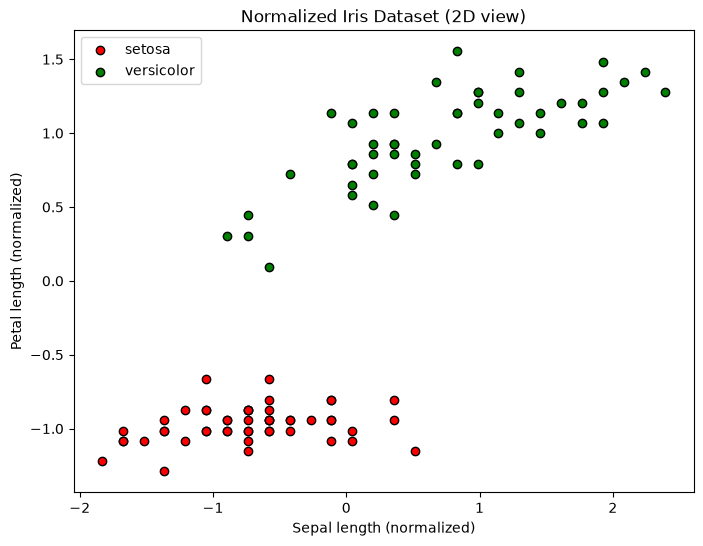

--- Training 4-Feature RBF SVM (Original) ---
Found 10 support vectors for rbf kernel.

Classification Report (4-Feature RBF):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      1.00      1.00        15

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Accuracy: 1.0000

--- Training 2-Feature Models for Visualization ---
Found 9 support vectors for rbf kernel.
Found 5 support vectors for linear kernel.


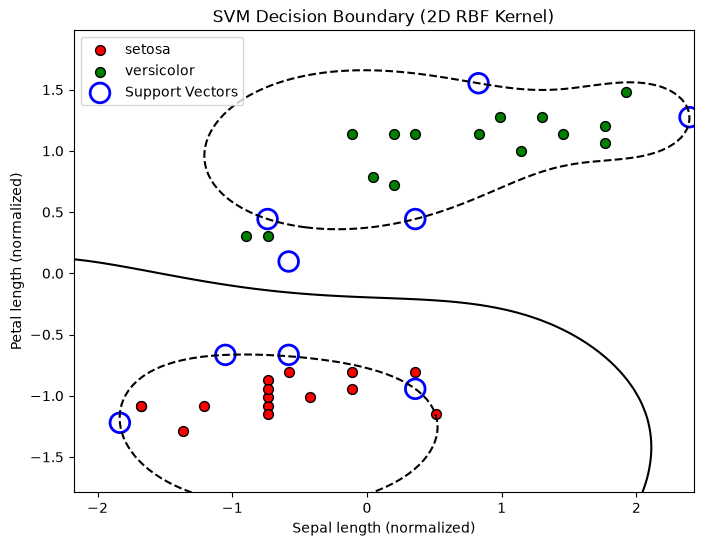

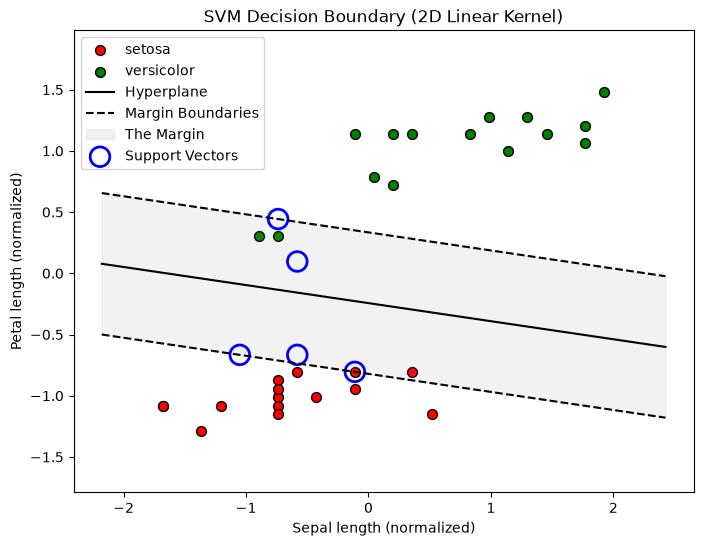


--- Training 3-Feature Model for Visualization ---
Found 3 support vectors for linear kernel.


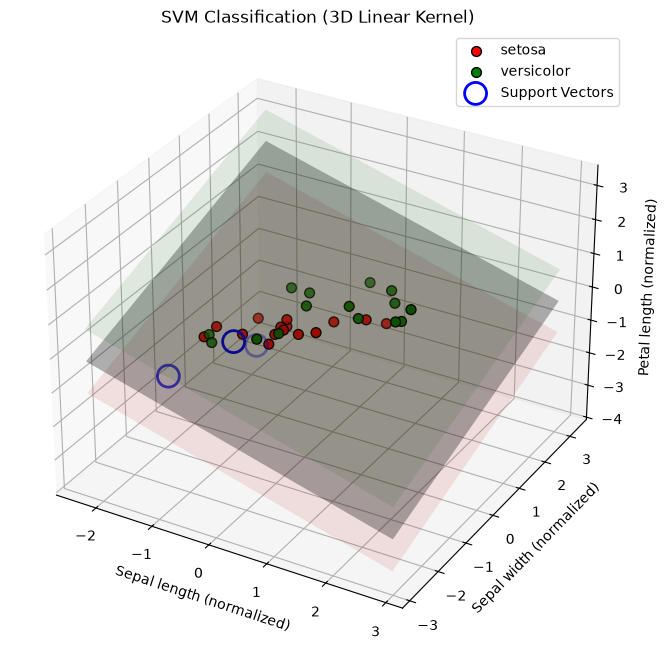

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler
from cvxopt import matrix, solvers

# ----------------------------
# Step 1: Load the Iris dataset
# ----------------------------
iris = load_iris()
X = iris.data  # features
y = iris.target  # labels

# binary classification: Setosa vs Versicolor -->simply for SVM
# by masking 0,1 --> flitter out 2
binary_mask = y != 2
X = X[binary_mask]
y = y[binary_mask]


# .copy --> save a copy of orginal data of y
original_y_numerical = y.copy() 

# Convert labels to -1 and 1 as required by the SVM formulation
# np.where(if condiction, when true, when false)
y = np.where(y == 0, -1, 1)

# ----------------------------
# Step 1a: Normalization (Standardization)
# ----------------------------
scaler = StandardScaler()
X = scaler.fit_transform(X)  # Scale the entire feature set

# Convert to pandas DataFrame for display
# add column at the top of the table/dataframe
df = pd.DataFrame(X, columns=iris.feature_names)

# add new row at left-hand-side 
df['species'] = np.where(original_y_numerical == 0, 'setosa', 'versicolor')

# pd. --> pandas for structure the table/dataframe
# np. --> numpy for pure numerical array

# print("First 10 rows of the normalized Iris dataset:")
# print(df.head(10))

# ----------------------------
# Step 1b: Visualize raw dataset (after normalization)
# ----------------------------
plt.figure(figsize=(8, 6))

# dictionary : directly set the color and name
colors_map = {-1: 'red', 1: 'green'}
label_names_map = {-1: 'setosa', 1: 'versicolor'}

# np.unique --> delet repeat num --> result : [-1, 1]
unique_labels_initial = np.unique(y)

for label in unique_labels_initial:
    plt.scatter(X[y == label, 0], X[y == label, 2],
                c=colors_map[label], label=label_names_map[label], edgecolor='k')
plt.xlabel('Sepal length (normalized)')
plt.ylabel('Petal length (normalized)')
plt.title('Normalized Iris Dataset (2D view)')
plt.legend()
plt.show()

# ----------------------------
# Step 2: Train-test split
# ----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# ----------------------------
# Step 3: Custom Soft-Margin SVM Implementation (HOMEWORK)
# ----------------------------
class SoftMarginSVM:
    def __init__(self, C=1.0, kernel='rbf', gamma=1.0):
        self.C = C
        self.gamma = gamma
        self.kernel_type = kernel
        self.kernel_func = self._get_kernel()

        self.alphas = None
        self.support_vectors = None
        self.support_vector_labels = None
        self.b = None
        self.w = None # Will only be set for linear kernel

    def linear_kernel(self, x1, x2):
         # dot product of x1 and x2
         # flatten() --> transform 2D dataset into 1D
        return np.dot(x1.flatten(), x2.flatten())

    def rbf_kernel(self, x1, x2):
        # Formula: exp(-gamma * ||x1 - x2||^2)
        dist_sq = np.linalg.norm(x1.flatten() - x2.flatten()) ** 2
        return np.exp(-self.gamma * dist_sq)

    def _get_kernel(self):
        # If self.kernel_type is 'linear', return self.linear_kernel
        # If self.kernel_type is 'rbf', return self.rbf_kernel
        # Otherwise, raise a ValueError.
        if self.kernel_type == 'linear' :
            return self.linear_kernel
        elif self.kernel_type == 'rbf' :
            return self.rbf_kernel
        else :
            raise ValueError(f"Unsupported kernel type: {self.kernel_type}")

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # --- 1. Compute the Kernel Matrix K ---
        # Initialize K as an (n_samples, n_samples) matrix of zeros.
        K = np.zeros((n_samples, n_samples))
        
        # Fill K[i, j] with the result of self.kernel_func(X[i], X[j])
        for i in range(n_samples):
            for j in range(n_samples):
                 K[i, j] = self.kernel_func(X[i], X[j])

        # --- 2. Set up the Quadratic Programming (QP) problem ---
        # min 1/2 * a^T * P * a + q^T * a
        # Subject to: G*a <= h and A*a = b_mat

        # outer -->cross product
        P = matrix(np.outer(y, y) * K, tc = 'd') 

        #set a column vector with -1
        q = matrix(-np.ones((n_samples, 1)), tc = 'd')

        # Create A (for equality constraint y^T * a = 0)
        # set y into row vector [1 * N]
        A = matrix(y, (1, n_samples), tc = 'd')

        # set const on the right side of the "=" into 0.0
        b_mat = matrix(0.0, tc = 'd')

        # Create G (for inequality constraints 0 <= a_i <= C)
        # 2 constraints for each alpha:
        # 1) -a_i <= 0  (which is a_i >= 0)
        # 2)  a_i <= C
        
        # Diagonal matrix
        G_lower = np.diag(np.ones(n_samples) * -1)
        G_upper = np.diag(np.ones(n_samples))
        
        # .vstack --> vertical stack 
        G = matrix(np.vstack((G_lower, G_upper)), tc = 'd')

        # Create h (for inequality constraints)
        # Hint: Use np.zeros(n_samples) for the lower bound (for -a_i <= 0)
        #       and np.ones(n_samples) * self.C for the upper bound (for a_i <= C).
        #       Then stack them with np.hstack.
        h_lower = np.zeros(n_samples)
        h_upper = np.ones(n_samples) * self.C
        h = matrix(np.hstack((h_lower, h_upper)), tc = 'd')

        # --- 3. Solve the QP problem ---
        solvers.options['show_progress'] = False

        # Call the QP solver
        solution = solvers.qp(P, q, G, h, A, b_mat)

        # Check if a solution was found. If not, handle the error.
        # We assume it's found
        alphas = np.ravel(solution['x'])

        # --- 4. Find Support Vectors ---
        # Support vectors are samples where alpha > tolerance (e.g., 1e-5)
        tol = 1e-5

        # boolean mask 'sv_indices' for alphas > tol
        sv_indices = alphas > tol

        # Store the support vector alphas, X values, and y labels.
        self.alphas = alphas[sv_indices]
        self.support_vectors = X[sv_indices]
        self.support_vector_labels = y[sv_indices]

        print(f"Found {len(self.support_vectors)} support vectors for {self.kernel_type} kernel.")

        # --- 5. Compute the bias 'b' ---
        # use any support vector *on the margin* (0 < alpha < C)
        # Formula: b = y_k - sum(a_i * y_i * K(x_i, x_k))
        # ( k is the index of a margin SV, and the sum is over all SVs)

        # margin SVs (tol < alphas < C - tol)
        margin_sv_indices = (alphas > tol) & (alphas < self.C - tol)

        
        if np.any(margin_sv_indices): 
            k = np.where(margin_sv_indices)[0][0]
            b_sum = 0
            
            for j in range(len(self.alphas)):
                 b_sum += (self.kernel_func(self.support_vectors[j], X[k]) * self.alphas[j] * self.support_vector_labels[j])

            self.b = y[k] - b_sum

        else:
            print("Warning: No support vectors on the margin. 'b' may be less stable.")
            self.b = 0.0 

        # --- 6. Compute weights 'w' (ONLY for linear kernel) ---
        # Formula: w = sum(a_i * y_i * x_i)

        if self.kernel_type == 'linear':
            # Initialize self.w as a zero vector of size n_features
            self.w = np.zeros(n_features)

            # Calculate W
            for i in range(len(self.alphas)):
                 self.w += self.alphas[i] * self.support_vector_labels[i] * self.support_vectors[i]
            

    def decision_function(self, X):
        # Formula: f(x) = sum(a_i * y_i * K(x_i, x)) + b
        n_samples = X.shape[0]
        scores = []

        
        for x_new in X:
             s = 0
            # TODO: Loop over all support vectors
             for i in range(len(self.support_vectors)):
                 s += (self.alphas[i] * self.support_vector_labels[i] * self.kernel_func(self.support_vectors[i], x_new))
             scores.append(s + self.b)

        return np.array(scores)

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


# ----------------------------
# Step 4: Train & Evaluate Original Model (4-feature RBF)
# ----------------------------
print("--- Training 4-Feature RBF SVM (Original) ---")
model_4d_rbf = SoftMarginSVM(C=1.0, kernel='rbf', gamma=0.1)
model_4d_rbf.fit(X_train, y_train)
y_pred = model_4d_rbf.predict(X_test)

print("\nClassification Report (4-Feature RBF):")
# Note: This will fail until the students implement the class!
print(classification_report(y_test, y_pred, target_names=['setosa', 'versicolor']))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")


# ----------------------------
# Step 5: Visualization (2D)
# ----------------------------
# To plot a 2D boundary, we MUST train a 2D model.
# We will use features 0 (Sepal length) and 2 (Petal length)
print("\n--- Training 2-Feature Models for Visualization ---")
X_train_2d = X_train[:, [0, 2]]
X_test_2d = X_test[:, [0, 2]]
x_label = 'Sepal length (normalized)'
y_label = 'Petal length (normalized)'

# 2D Model 1: RBF Kernel (Non-linear boundary)
model_2d_rbf = SoftMarginSVM(C=1.0, kernel='rbf', gamma=0.5)
model_2d_rbf.fit(X_train_2d, y_train)

# 2D Model 2: Linear Kernel (Linear hyperplane)
model_2d_lin = SoftMarginSVM(C=1.0, kernel='linear')
model_2d_lin.fit(X_train_2d, y_train)

# Helper function to plot 2D data
def plot_2d_data(ax, X, y, title):
    for label in np.unique(y):
        ax.scatter(X[y == label, 0], X[y == label, 1],
                   c=colors_map[label], label=label_names_map[label],
                   edgecolor='k', s=50)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    # ax.legend() # We will call legend() later after all items are added

# --- Plot 1: 2D RBF (Curved Boundary) ---
fig, ax = plt.subplots(figsize=(8, 6))
plot_2d_data(ax, X_test_2d, y_test, 'SVM Decision Boundary (2D RBF Kernel)')

# Create meshgrid to plot boundary
x_min, x_max = X_test_2d[:, 0].min() - 0.5, X_test_2d[:, 0].max() + 0.5
y_min, y_max = X_test_2d[:, 1].min() - 0.5, X_test_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                     np.linspace(y_min, y_max, 100))

# Get decision function scores
Z = model_2d_rbf.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary and margins
ax.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'], colors='black')
# Plot support vectors
sv = model_2d_rbf.support_vectors
ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolors='none', edgecolors='blue',
           label='Support Vectors', lw=2)
ax.legend()
plt.show()

# --- Plot 2: 2D Linear (Flat Hyperplane) ---
fig, ax = plt.subplots(figsize=(8, 6))
plot_2d_data(ax, X_test_2d, y_test, 'SVM Decision Boundary (2D Linear Kernel)')

# Plot hyperplane and margins
w = model_2d_lin.w
b = model_2d_lin.b

x_plot = np.linspace(x_min, x_max, 10)
# w[0]*x + w[1]*y + b = 0  => y = (-w[0]*x - b) / w[1]
y_plot = (-w[0] * x_plot - b) / w[1]
# w[0]*x + w[1]*y + b = 1  => y = (1 - w[0]*x - b) / w[1]
y_plot_plus1 = (1 - w[0] * x_plot - b) / w[1]
# w[0]*x + w[1]*y + b = -1 => y = (-1 - w[0]*x - b) / w[1]
y_plot_minus1 = (-1 - w[0] * x_plot - b) / w[1]

# Plot the hyperplane
ax.plot(x_plot, y_plot, 'k-', label='Hyperplane')

# Plot the margin boundaries
ax.plot(x_plot, y_plot_plus1, 'k--', label='Margin Boundaries')
ax.plot(x_plot, y_plot_minus1, 'k--') # No label for second line

# Plot the margin itself (the "street")
ax.fill_between(x_plot, y_plot_minus1, y_plot_plus1,
                color='gray', alpha=0.1, label='The Margin')

# Plot support vectors
sv = model_2d_lin.support_vectors
ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolors='none', edgecolors='blue',
           label='Support Vectors', lw=2)

ax.set_ylim(y_min, y_max) # Keep plot focused
ax.legend()
plt.show()


# ----------------------------
# Step 6: Visualization (3D)
# ----------------------------
# To plot a 3D boundary, we must train a 3D model.
# We will use features 0, 1, and 2
print("\n--- Training 3-Feature Model for Visualization ---")
X_train_3d = X_train[:, [0, 1, 2]]
X_test_3d = X_test[:, [0, 1, 2]]
x_label_3d = 'Sepal length (normalized)'
y_label_3d = 'Sepal width (normalized)'
z_label_3d = 'Petal length (normalized)'

# We will only plot the 3D LINEAR model
# Plotting a 3D non-linear (RBF) boundary surface is very complex
model_3d_lin = SoftMarginSVM(C=1.0, kernel='linear')
model_3d_lin.fit(X_train_3d, y_train)

# --- Plot 3: 3D Linear (Flat Hyperplane) ---
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot test data
for label in np.unique(y_test):
    ax.scatter(X_test_3d[y_test == label, 0],
               X_test_3d[y_test == label, 1],
               X_test_3d[y_test == label, 2],
               c=colors_map[label],
               label=label_names_map[label],
               edgecolor='k', s=50)

# Plot support vectors
sv_3d = model_3d_lin.support_vectors
ax.scatter(sv_3d[:, 0], sv_3d[:, 1], sv_3d[:, 2],
           s=250, facecolors='none', edgecolors='blue',
           label='Support Vectors', lw=2)

# Create grid for plane
x_min_3d, x_max_3d = X_train_3d[:, 0].min() - 0.5, X_train_3d[:, 0].max() + 0.5
y_min_3d, y_max_3d = X_train_3d[:, 1].min() - 0.5, X_train_3d[:, 1].max() + 0.5

xx_3d, yy_3d = np.meshgrid(np.linspace(x_min_3d, x_max_3d, 10),
                           np.linspace(y_min_3d, y_max_3d, 10))

# Get weights and bias
w_3d = model_3d_lin.w
b_3d = model_3d_lin.b

# w[0]*x + w[1]*y + w[2]*z + b = 0 => z = (-w[0]*x - w[1]*y - b) / w[2]
zz_hyperplane = (-w_3d[0] * xx_3d - w_3d[1] * yy_3d - b_3d) / w_3d[2]
zz_margin_plus = (1 - w_3d[0] * xx_3d - w_3d[1] * yy_3d - b_3d) / w_3d[2]
zz_margin_minus = (-1 - w_3d[0] * xx_3d - w_3d[1] * yy_3d - b_3d) / w_3d[2]

# Plot the surfaces
ax.plot_surface(xx_3d, yy_3d, zz_hyperplane, alpha=0.3, color='black', rstride=100, cstride=100)
ax.plot_surface(xx_3d, yy_3d, zz_margin_plus, alpha=0.1, color='green', rstride=100, cstride=100)
ax.plot_surface(xx_3d, yy_3d, zz_margin_minus, alpha=0.1, color='red', rstride=100, cstride=100)

ax.set_xlabel(x_label_3d)
ax.set_ylabel(y_label_3d)
ax.set_zlabel(z_label_3d)
ax.set_title('SVM Classification (3D Linear Kernel)')
ax.legend()
plt.show()

## **Answer**

1. Mapping low-dimensional data into higher-dimentional  space, and computing inner product via kernel trick to save computational cost.

    Use to solve non-linearly separable classification problem, where straight line or flat hyperplane cannot separate the data in orginal space.

2.  By adding Slack variables, it allows part of the data violated the margin or missclassified to achieve Soft margin.

    C controls penalty for errors   

        → high C = narrow margin of overfitting
        → low C = wide margin of underfitting   
        
    Using cross-validation to find the optimize constant C.

3. Support Vectors decide the decision boundary.

    Support Vectors : points closest to the hyperplane 

    → including : the one on the margin edge, inside margin, and misclassified points

